In [1]:
# reload modules before execution (for the changing code in src)
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib as mpl

from itertools import product

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import time

import warnings

import src.submatrix as submatrix

# Heuristics development lab

## Adaptive pruning, one axis

In [3]:
def pretty_heatmap(matrix: np.ndarray,
                   annotation: bool = False):
    
    fig, ax = plt.subplots(figsize=(8,10))

    cmap = mpl.colormaps['hot']
    im = ax.imshow(matrix, cmap=cmap)
    
    if annotation:
        for i in range(matrix.shape[0]):
            for j in range(matrix.shape[1]):
                ax.text(j, i, matrix[i,j], ha="center", va="center")
    
    ax.set_xticks(range(matrix.shape[1]))
    ax.set_yticks(range(matrix.shape[0]))

    # Turn spines off and create a grid
    ax.spines[:].set_visible(False)

    ax.set_xticks(np.arange(matrix.shape[1]+1)-.5, minor=True)
    ax.set_yticks(np.arange(matrix.shape[0]+1)-.5, minor=True)
    ax.grid(which="minor", color="grey", linestyle='-', linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    
    plt.colorbar(im, ax = ax, fraction=0.036)
    fig.tight_layout()
    plt.show()

In [4]:
def biclique_coverage(
    matrix: np.ndarray,
    results: pd.DataFrame    
):
    cov =  np.zeros_like(matrix)

    for rows, cols in zip(results['found_rows'], results['found_cols']):
        rows = np.asarray(rows, dtype=int).ravel()
        cols = np.asarray(cols, dtype=int).ravel()
        cov[np.ix_(rows, cols)] += 1

    miss = np.isnan(matrix)

    # raise ValueError if any missing element has coverage
    if np.count_nonzero((cov > 0) & miss) > 0:
        raise ValueError("A biclique contains a missing element")
    
    return np.count_nonzero(cov) / (~miss).sum()

In [5]:
def eligibility_matrix(matrix: np.ndarray, q: int = 2) -> np.ndarray:
    
    obs = (~np.isnan(matrix)).astype(np.int32)
    shared_counts = obs @ obs.T

    eligible = shared_counts >= q
    np.fill_diagonal(eligible, False)

    return eligible

In [6]:
def biclique_pair_coverage(matrix: np.ndarray, 
                           results: pd.DataFrame):
    n = matrix.shape[0]
    cov = np.zeros((n,n))

    for rows in results['found_rows']:
        rows = np.asarray(rows, dtype=int).ravel()
        cov[np.ix_(rows, rows)] += 1

    np.fill_diagonal(cov, 0)

    return cov > 0

In [7]:
# prepare a matrix
alpha = 0.5 # P(in a complete matrix|element is observed) = alpha
miss = 0.3 # P(element is missing)

# complete relative aspect ratio
# 1 is the same as the encompassing matrix
q = 1

# big dimensions
n = 160
d = 280

# complete dimensions
x, y = submatrix.calculate_complete_dims(alpha, miss, q, n, d)
print(x, y)

seed = 123

matrix = submatrix.generate_matrix_with_planted(n, d, x, y, seed, miss)

df_matrix = pd.DataFrame(matrix)
missing_matrix = np.isnan(matrix)

94 165


In [8]:
eligible_pairs = eligibility_matrix(matrix)

u_tri_idx = np.triu_indices_from(eligible_pairs)
elig_pairs_no = eligible_pairs[u_tri_idx].sum()
elig_pairs_no

np.int64(12720)

In [9]:
results = []

T = 1000
thresholds = np.linspace(0.1, 1, num= 20, endpoint=False)

for threshold in thresholds:
    found_elements = np.zeros((n, d), dtype=int)
    for t in range(T):
        found_rows, found_cols = submatrix.random_prune_to_complete(matrix, threshold_coeff=threshold)
        #print(len(found_rows), len(found_cols))
        if found_rows is not None and found_cols is not None:
            if len(found_rows) >= 3:
                found_elements[np.ix_(found_rows, found_cols)] += 1
                results.append({
                    'threshold': threshold,
                    'found_rows': found_rows,
                    'found_rows_no': len(found_rows),
                    'found_cols': found_cols,
                    'found_cols_no': len(found_cols)
                })
    
    found_elements[missing_matrix] -= 100
    #found_elements /= 100
    #print(threshold)
    #pretty_heatmap(found_elements, annotation=True)

KeyboardInterrupt: 

In [233]:
results = pd.DataFrame(results)
#results = results.sort_values(by=['threshold', 'found_rows_no', 'found_cols_no'], ascending=[True, False, False])

In [234]:
thresholds = results['threshold'].unique()
cov_per_threshold = []
cov_elig_pairs_per_threshold = []
for threshold in thresholds:
    t_mask = results['threshold'] == threshold

    cov_eligible_pairs = (biclique_pair_coverage(matrix, results[t_mask]) & eligible_pairs)
    cov_eligible_pairs = np.count_nonzero(cov_eligible_pairs) / 2
    
    cov_per_threshold.append({
        'threshold': threshold,
        'coverage': biclique_coverage(matrix, results[t_mask]),
        'cov_eli_pairs_frac': cov_eligible_pairs / elig_pairs_no
    })

o_cov = biclique_coverage(matrix, results)
o_pair_cov = biclique_pair_coverage(matrix, results)

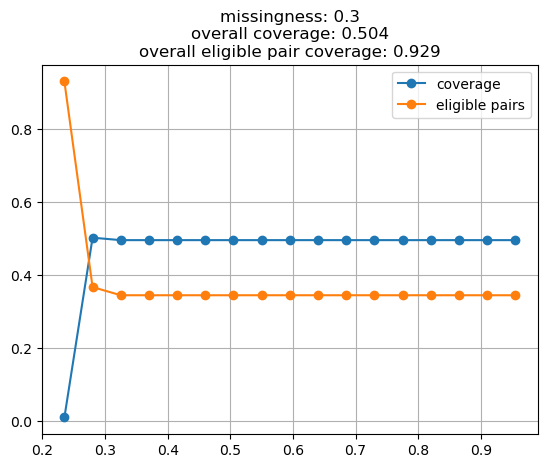

In [235]:
cov_per_threshold = pd.DataFrame(cov_per_threshold)
plt.plot(cov_per_threshold['threshold'], cov_per_threshold['coverage'], marker = 'o', label = 'coverage')
plt.plot(cov_per_threshold['threshold'], cov_per_threshold['cov_eli_pairs_frac'], marker = 'o', label = 'eligible pairs')
plt.title(f"missingness: {miss}\noverall coverage: {o_cov:.3f}\noverall eligible pair coverage: {(o_pair_cov.sum()/2)/elig_pairs_no:.3f}")
plt.legend()
plt.grid(True)
plt.show()

## Basic pruning

In [3]:
def basic_prune_to_complete_mem_effective(matrix: np.array):
    no_rows, no_cols = matrix.shape
    matrix = np.isnan(matrix)

    # no of missing elements in the whole matrix
    no_missing = int(matrix.sum())

    # no of missing elements per row
    row_missing = matrix.sum(axis=1)
    # no of missing elements per col
    col_missing = matrix.sum(axis=0)
    
    i = 0
    while (no_cols != 0 and no_rows != 0) and no_missing != 0:
        # remove worst column or row in one iteration
        # remove a column
        if max(col_missing / no_cols) >= max(row_missing / no_rows):
            # index of the worst column
            worst_col = np.argmax(col_missing)
            # update total missing count
            no_missing -= col_missing[worst_col]
            # update row counts
            row_missing -= matrix[:, worst_col]
            # remove the missing column
            # setting the number of missing elements to -1
            # effectively renders it inactive
            col_missing[worst_col] = -1
            # update column count
            no_cols -= 1
        
        # remove a row
        else:
            # index of the worst row
            worst_row = np.argmax(row_missing)
            # update total missing count
            no_missing -= row_missing[worst_row]
            # update column counts
            col_missing -= matrix[worst_row, :]
            # remove the missing row
            # setting the number of missing elements to -1
            # effectively renders it inactive
            row_missing[worst_row] = -1
            # update row count
            no_rows -= 1
        
        i += 1
    print(no_missing)
    print(row_missing)
    print(col_missing)
    row_idx = np.flatnonzero(row_missing == 0)
    col_idx = np.flatnonzero(col_missing == 0)
    return row_idx, col_idx

In [83]:
n, d = (5, 7)
x, y = (4, 3)
frac_missing = 0.4
rng  = np.random.default_rng()
matrix = submatrix.generate_matrix_with_planted(n, d, x, y, seed=rng.integers(1, 32), frac_missing=frac_missing)

row_idx, col_idx, ii = submatrix.adaptive_prune_to_complete_with_completion(pd.DataFrame(matrix), shrink_coeff=2, max_iter=1000)
#matrix[np.ix_(row_idx, col_idx)]

In [84]:
print(row_idx)
print(col_idx)
print(ii)

Index([0, 2, 3, 4], dtype='int64')
Index([0, 2, 4, 5], dtype='int64')
   i  no_pruned_rows  no_pruned_cols  eff_lr  missing_no  missing_frac
0  1               1               3     0.5           0           0.0


## Experiment design

In [66]:
#short_sides = [30, 60, 120, 250, 500, 1000]
short_sides = [30]
missingness = [0.3, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.975, 0.99]
planted_relative_aspects = [ 
    0.35,     # relatively wide
    1.0,      # same relative shape as the host
    2.8,      # relatively tall
]
alpha = 0.5
T = 10
Cs = np.hstack((np.arange(1, 10), np.arange(10, 100, 10), np.arange(100, 301, 20)))

In [143]:
start_seed = 1
for ss in short_sides:
    big_dims = submatrix.prepare_big_dims(short_sides)
    
    complete_dims = {}
    
    for n, d in big_dims:
        for m in missingness:
            temp = []
            for a in planted_relative_aspects:
                temp_compl_dims = submatrix.calculate_complete_dims(alpha, m, a, n, d)
                if temp_compl_dims is not None:
                    temp.append(temp_compl_dims)
    
            complete_dims[(n, d), m] = temp
    
    tasks = [ (big, complete, missing) for (big, missing), complete_dims_list in complete_dims.items() for complete in complete_dims_list]
    print(f"No of tested matrices: {len(tasks)}.")
    # Repeat each matrix experiment T times
    tasks = [(*task, t) for task in tasks for t in range(T)]
    # assign each unique matrix a seed
    tasks = [(*task, seed, Cs) for seed, task in enumerate(tasks, start = start_seed)]
    print(f"No of experiments (unique matrices): {len(tasks)}")
    start_seed += len(tasks)

No of tested matrices: 135.
No of experiments (unique matrices): 1350


In [144]:
tasks[0]

((30, 30),
 (10, 30),
 0.3,
 0,
 1,
 array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  20,  30,  40,
         50,  60,  70,  80,  90, 100, 120, 140, 160, 180, 200, 220, 240,
        260, 280, 300]))

## Results analysis

In [4]:
# 2000x3000
# results_file = Path("../results/submatrix_planted_results_20260711_193602.txt").resolve()

# final experiment, small matrices
# results_file_name = "submatrix_planted_results_20260713_114156.csv"

# results with basic_prune_to_complete
# results_file_name = "submatrix_planted_results_20260715_111048.csv"

# with reintroducing rows and columns
results_file_name = "submatrix_planted_results_20260715_194913.csv"

results_folder = Path("../results/benchmarking_submatrices/").resolve()
results = pd.read_csv(results_folder / results_file_name)

In [5]:
total_len = len(results)
basic_mask = results['C'] == -1
basic_results = results[basic_mask]
results = results[~basic_mask]

assert len(basic_results) + len(results) == total_len

### Extract distinct results achieved at the smallest C

In [92]:
# TODO disctinct result should be distinct subset of rows and cols, not distinct size, as it is now
distinct_results = []

seeds = results["seed"].unique()
for seed in seeds:
    seed_mask = results["seed"] == seed
    distinct_results.append(submatrix.distinct_solutions(results[seed_mask]))

distinct_results = pd.concat(distinct_results).reset_index()

In [93]:
# no of cases with no solution found
no_solutions_no = len(seeds) - len(distinct_results['seed'].unique())
print(f"Out of {len(seeds)} matrices, no adaptive solution was found for {no_solutions_no} ({no_solutions_no/len(seeds) * 100:.1f}%).")

Out of 5400 matrices, no adaptive solution was found for 86 (1.6%).


In [94]:
no_solutions_no = (basic_results['found_area'] == -1).sum()
print(f"Out of {len(basic_results)} matrices, no basic solution was found for {no_solutions_no} ({no_solutions_no/len(basic_results) * 100:.1f}%).")

Out of 5400 matrices, no basic solution was found for 0 (0.0%).


### Basic pruning results

In [95]:
basic_results['excess'] = basic_results['found_area']/(basic_results['complete_rows'] * basic_results['complete_cols']) - 1

In [96]:
# fraction of experiments arriving at better than planted solution
print(len(basic_results[basic_results['excess'] > 0])/len(basic_results))
# fraction of experiments arriving at at least as good as planted solution
print(len(basic_results[basic_results['excess'] >= 0])/len(basic_results))
# fraction of experiments arriving at at least 80% of planted area solution
print(len(basic_results[basic_results['excess'] >= -0.2])/len(basic_results))

0.003703703703703704
0.9990740740740741
0.9992592592592593


### Extract largest area results for each matrix from adaptive pruning

In [97]:
largest_area_results = (
    distinct_results.loc[distinct_results.groupby(by='seed')['found_area'].idxmax(), 
        ['found_area', 'row_cnt', 'col_cnt', 'time_sec', 'C', 'complete_rows', 'complete_cols', 'missingness', 'big_rows', 'big_cols', 'seed']
    ]
)
largest_area_results['excess'] = (
    largest_area_results['found_area'] / 
    (largest_area_results['complete_rows'] * largest_area_results['complete_cols']) - 1
)

#### Compare results against the conservative pruning baseline

In [98]:
largest_area_results_with_basic = pd.merge(largest_area_results, 
             basic_results[['row_cnt', 'col_cnt', 'found_area', 'seed']], 
             on='seed', 
             suffixes=('', '_basic'))
largest_area_results_with_basic['basic_excess'] = (
    largest_area_results_with_basic['found_area_basic'] 
    / (largest_area_results_with_basic['complete_rows'] * largest_area_results_with_basic['complete_cols']) 
    - 1
)

In [99]:
adaptive_better = (largest_area_results_with_basic['found_area'] > largest_area_results_with_basic['found_area_basic']).sum()
adaptive_same = (largest_area_results_with_basic['found_area'] == largest_area_results_with_basic['found_area_basic']).sum()
adaptive_08 = (largest_area_results_with_basic['found_area'] >= 0.8 * largest_area_results_with_basic['found_area_basic']).sum()
print(f"Adaptive pruning returned {adaptive_better/len(seeds) * 100:.1f}% better solutions, {adaptive_same/len(seeds) * 100:1.0f}% same solutions and {adaptive_08/len(seeds) * 100:1.0f}% of solutions of at least 80% of base.")

Adaptive pruning returned 0.0% better solutions, 86% same solutions and 86% of solutions of at least 80% of base.


#### Compare results stratified by the missingness

In [100]:
# fraction of experiments arriving at better than planted solution
print(len(largest_area_results[largest_area_results['excess'] > 0])/len(largest_area_results))
# fraction of experiments arriving at at least as good as planted solution
print(len(largest_area_results[largest_area_results['excess'] >= 0])/len(largest_area_results))
# fraction of experiments arriving at at least 80% of planted area solution
print(len(largest_area_results[largest_area_results['excess'] >= -0.2])/len(largest_area_results))

0.0020700037636432068
0.8694015807301467
0.8720361309747836


In [101]:
summary_by_missingness = (
    largest_area_results.groupby(by='missingness', as_index=False)
    .agg(
        n_experiments=('excess', 'size'),
        frac_g_planted=(
            'excess',
            lambda x: x.gt(0).mean()
        ),
        frac_ge_planted=(
            'excess',
            lambda x: x.ge(0).mean()
        ),
        frac_ge_08_planted=(
            'excess',
            lambda x: x.ge(-0.2).mean()
        ),
        frac_ge_05_planted=(
            'excess',
            lambda x: x.ge(-0.5).mean()
        ),
        mean_excess=('excess', 'mean'),
        median_excess=('excess', 'median'),
        min_excess=('excess', 'min'),
        max_excess=('excess', 'max'),
        p10_excess=('excess', lambda x: x.quantile(0.10)),
        p90_excess=('excess', lambda x: x.quantile(0.90))
    )
)

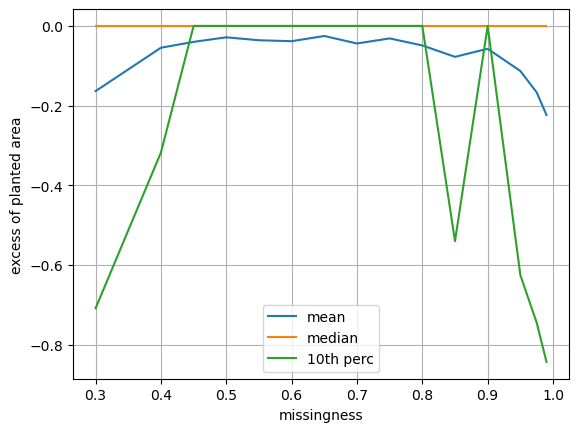

In [102]:
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['mean_excess'], label='mean')
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['median_excess'], label='median')
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['p10_excess'], label='10th perc')
# plt.plot(summary_by_missingness['missingness'], summary_by_missingness['p90_excess'], label='90th perc')
plt.xlabel("missingness")
plt.ylabel("excess of planted area")
plt.grid(True)
plt.legend()
plt.show()

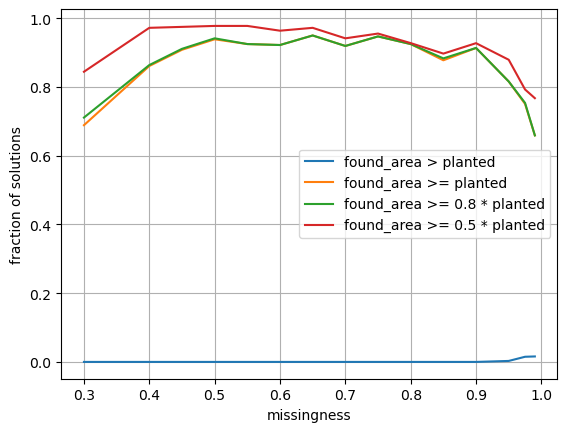

In [103]:
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['frac_g_planted'], label='found_area > planted')
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['frac_ge_planted'], label='found_area >= planted')
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['frac_ge_08_planted'], label='found_area >= 0.8 * planted')
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['frac_ge_05_planted'], label='found_area >= 0.5 * planted')
plt.xlabel("missingness")
plt.ylabel("fraction of solutions")
plt.grid(True)
plt.legend()
plt.show()

In [104]:
largest_area_results['big_area'] = largest_area_results['big_rows'] * largest_area_results['big_cols']

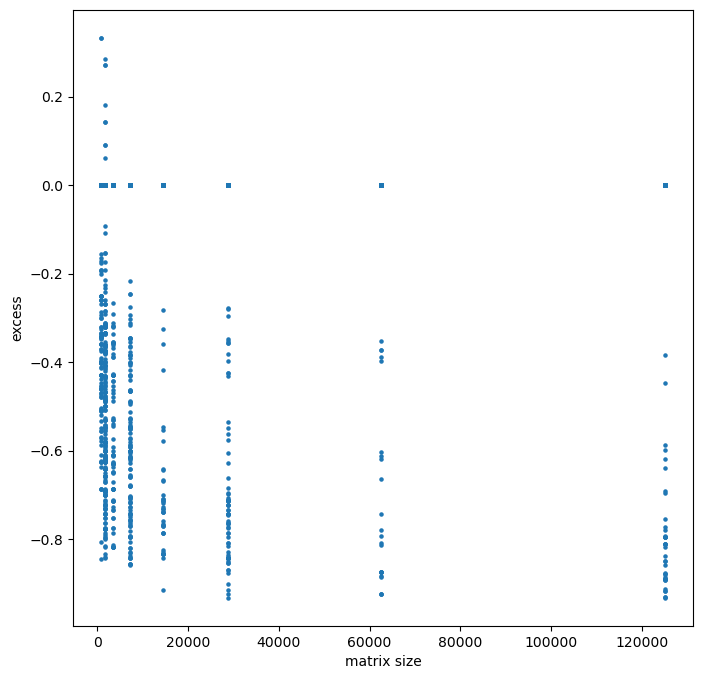

In [105]:
#mask = largest_area_results['excess'] < 3
#plot_df = largest_area_results[mask]
#mask = largest_area_results['missingness'] == 0.95
#plot_df = largest_area_results[mask]
plot_df = largest_area_results

fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(plot_df['big_area'], plot_df['excess'], s=5)
ax.set_xlabel("matrix size")
ax.set_ylabel("excess")
plt.show()

### Analysis of the results based on the C coefficient

In [106]:
# the largest C which produced the largest area result
largest_area_results['C'].max()

np.int64(240)

In [107]:
# analyze the row and col numbers from one solution
# right now they are disconnected
summary_by_C = (
    results
        .assign(row_frac=results['row_cnt']/results['big_rows'])
        .assign(col_frac=results['col_cnt']/results['big_cols'])
        .groupby(by='C', as_index=False)
        .agg(
            n=('time_sec', 'size'),
            max_row_frac = ('row_frac', 'max'),
            max_col_frac = ('col_frac', 'max'),
            mean_time = ('time_sec', 'mean'),
            median_time = ('time_sec', 'median')
        )
)

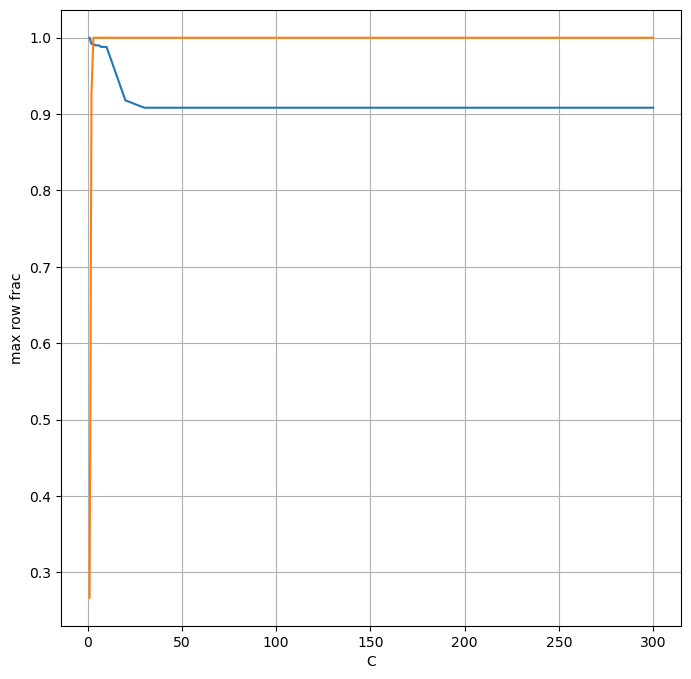

In [108]:
fig, ax = plt.subplots(figsize=(8,8))
ax.plot(summary_by_C['C'], summary_by_C['max_row_frac'])
ax.plot(summary_by_C['C'], summary_by_C['max_col_frac'])
ax.set_xlabel("C")
ax.set_ylabel("max row frac")
ax.grid(True)
plt.show()

### Extract the Pareto frontier solutions

In [109]:
Pareto_front = []

seeds = results["seed"].unique()
for seed in seeds:
    seed_mask = results["seed"] == seed
    Pareto_front.append(submatrix.Pareto_frontier(results[seed_mask]))

Pareto_front = pd.concat(Pareto_front).reset_index()

In [110]:
#TODO add an avg row measure and avg col measure and maybe avg area measure
# sTRONG bias instroduces for small Cs
# due to only a small C returnes even if larger C produced the same solution
summary_by_C = (
    Pareto_front
        .groupby(by='C', as_index=False)
        .agg(
            n=('time_sec', 'size'),
            mean_time = ('time_sec', 'mean'),
            median_time = ('time_sec', 'median')
        )
)

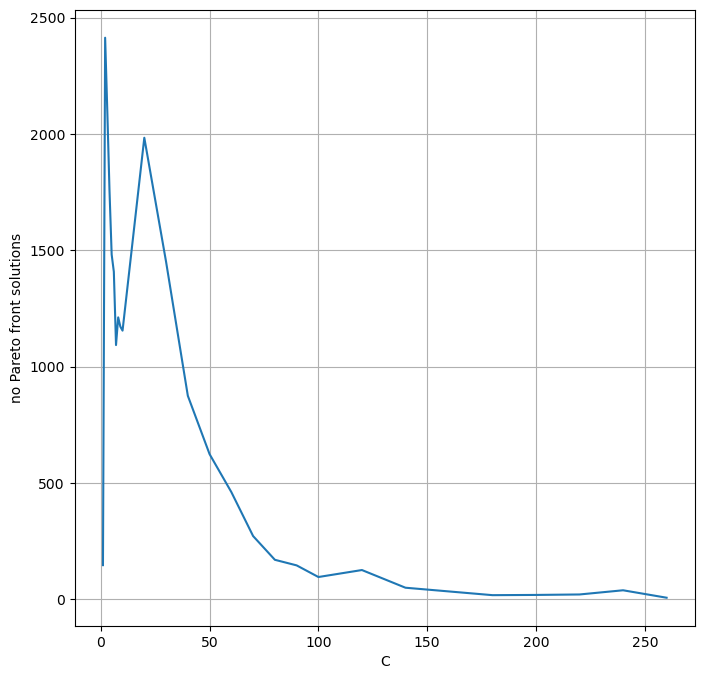

In [111]:
fig, ax = plt.subplots(figsize=(8,8))
ax.plot(summary_by_C['C'], summary_by_C['n'])
ax.set_xlabel("C")
ax.set_ylabel("no Pareto front solutions")
ax.grid(True)
plt.show()

# Balanced coverage

In [189]:
# prepare a matrix
alpha = 0.5
miss = 0.3
q = 1
n = 10
d = 12
x, y = submatrix.calculate_complete_dims(alpha, miss, q, n, d)
seed = 1234
matrix = submatrix.generate_matrix_with_planted(n, d, x, y, seed, miss)
df_matrix = pd.DataFrame(matrix)
missing_matrix = np.isnan(matrix)
print(x, y)

5 7


In [190]:
Cs = np.hstack((np.arange(1, 10), np.arange(10, 100, 10), np.arange(100, 301, 20)))

In [191]:
# seletion of bicliques
S = []
for C in Cs:
    found_rows, found_cols, ii = submatrix.adaptive_prune_to_complete_with_completion(df_matrix, shrink_coeff=C)
    S.append({
        'C': C,
        'found_rows': found_rows.values if found_rows is not None else None,
        'found_cols': found_cols.values if found_cols is not None else None,
        'ii': ii
    })
S_T = []
for C in Cs:
    found_rows, found_cols, ii = submatrix.adaptive_prune_to_complete_with_completion(df_matrix.T, shrink_coeff=C)
    S_T.append({
        'C': C,
        'found_rows': found_cols.values if found_rows is not None else None,
        'found_cols': found_rows.values if found_cols is not None else None,
        'ii': ii
    })

S = pd.DataFrame(S)
S_T = pd.DataFrame(S_T)

In [192]:
exposure = np.zeros((n, n))
coverage = np.zeros((n, d))
for C in Cs:
    rows = S.loc[result_mask, 'found_rows'].item()
    cols = S.loc[result_mask, 'found_cols'].item()
    
    if rows is not None and cols is not None:
        exposure[np.ix_(rows, rows)] += 1
        coverage[np.ix_(rows, cols)] += 1
for C in Cs:
    result_mask = S_T['C'] == C
    rows = S_T.loc[result_mask, 'found_rows'].item()
    cols = S_T.loc[result_mask, 'found_cols'].item()
    
    if rows is not None and cols is not None:
        exposure[np.ix_(rows, rows)] += 1
        coverage[np.ix_(rows, cols)] += 1

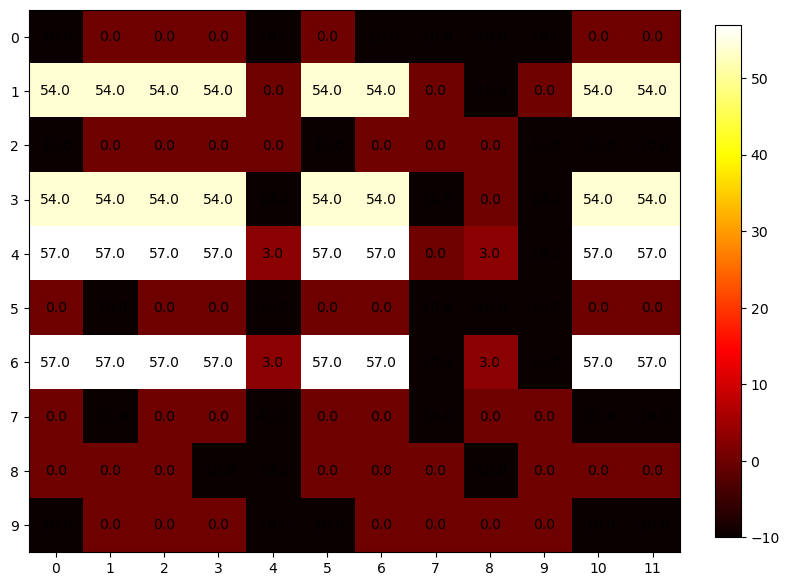

In [193]:
coverage[missing_matrix] = -10

fig, ax = plt.subplots(figsize=(8,8))

cmap = mpl.colormaps['hot']
im = ax.imshow(coverage, cmap=cmap)

for i in range(missing_matrix.shape[0]):
    for j in range(missing_matrix.shape[1]):
        ax.text(j, i, coverage[i,j], ha="center", va="center")

ax.set_xticks(range(missing_matrix.shape[1]))
ax.set_yticks(range(missing_matrix.shape[0]))

plt.colorbar(im, ax = ax, fraction=0.036)
fig.tight_layout()
plt.show()

In [194]:
rows, cols, _ = submatrix.basic_prune_to_complete_with_completion(matrix)
rows_T, cols_T, _ = submatrix.basic_prune_to_complete_with_completion(matrix.T)
print(rows, cols)
print(rows_T, cols_T)

[1 3 4 5 6 8] [ 0  2  5  6 10 11]
[ 0  2  5  6 10 11] [1 3 4 5 6 8]


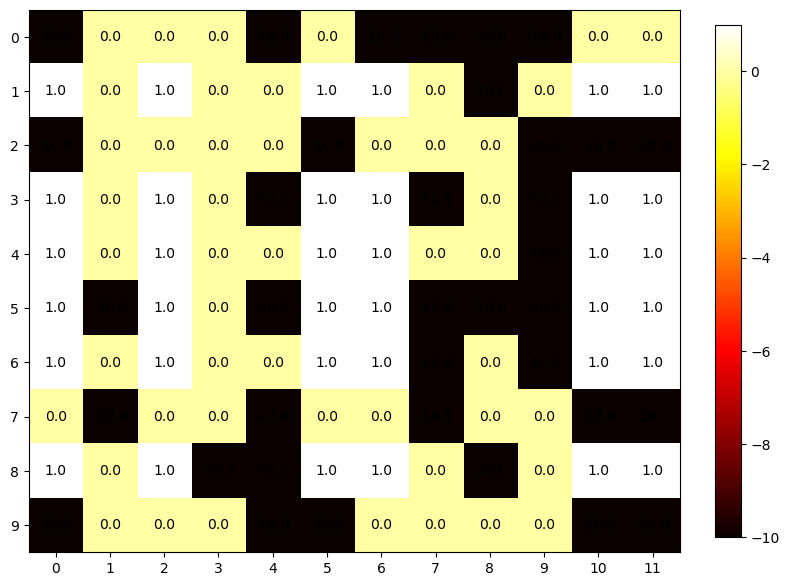

In [195]:
found_entries = np.zeros((n, d))
found_entries[missing_matrix] = -10
found_entries[np.ix_(rows, cols)] += 1
pretty_heatmap(found_entries, annotation=True)

# Exact benchmark

In [117]:
def read_matrix_solutions_from_file(matrix_file):
    with open(matrix_file) as mf:
        n_rows, n_cols = mf.readline().strip().split(" ")
        n_rows  = int(n_rows)
        n_cols = int(n_cols)
    
        matrix = np.empty((n_rows, n_cols), dtype = float)
        
        # read a matrix
        for i in range(n_rows):
            row = mf.readline().strip()
            matrix[i, :] = (np.frombuffer(row.encode('ascii'), dtype = np.uint8) == ord(b'1'))
        #the \n
        mf.readline()

        solutions = mf.readlines()
        solutions = np.array([line.strip().split() for line in solutions], dtype = 'uint32')
    return matrix, solutions

In [118]:
BENCHMARK_MATRICES_FOLDER = Path("../results/benchmark_matrices/").resolve()

In [119]:
#TODO add matrix size
#TODO add execution time

In [142]:
results = []

shs = np.hstack((np.arange(1, 10), np.arange(10, 100, 10), np.arange(100, 301, 20)))

for matrix_file in BENCHMARK_MATRICES_FOLDER.iterdir():
    matrix, solutions = read_matrix_solutions_from_file(matrix_file)

    df_matrix = pd.DataFrame(matrix)
    df_matrix[df_matrix == 0] = np.nan
    
    missingness = df_matrix.isna().sum().sum()/df_matrix.size
    if missingness == 1: continue

    if len(solutions) == 0: continue
    
    area = solutions[0][0].bit_count() * solutions[0][1].bit_count()
    
    best_submatrix_area = 0
    areas_ratio = 0
    '''
    for sh in shs:
        found_rows, found_cols, ii = submatrix.adaptive_prune_to_complete_with_completion(df_matrix, shrink_coeff=sh, max_iter=3000)
        if found_rows is None and found_cols is None: continue
        submatrix_area = len(found_rows) * len(found_cols)
        if best_submatrix_area < submatrix_area:
            best_submatrix_area = submatrix_area
            areas_ratio = best_submatrix_area / area
        if best_submatrix_area >= area:
            break

        if submatrix_area == area:
            for solution in solutions:
                row_mask = int(solution[0])
                row_indices = pd.Index([i for i in range(row_mask.bit_length()) if row_mask & (1 << i)])
                if row_indices.equals(pd.Index(found_rows)):
                    col_mask = int(solution[1])
                    col_indices = pd.Index([i for i in range(col_mask.bit_length()) if col_mask & (1 << i)])
                    if (col_indices == pd.Index(found_rows)).all():
                        pass
        '''
    found_rows, found_cols, ii = submatrix.basic_prune_to_complete_with_completion(matrix)
    results.append({
        "file": matrix_file.name,
        "matrix_area": matrix.size,
        "missing": missingness,
        "optimal_area": area,
        "submatrix_area": len(found_rows) * len(found_cols),
        "areas_ratio": (len(found_rows) * len(found_cols))/area,
    })

results = pd.DataFrame(results)

In [143]:
results = results.assign(opt_to_matrix=lambda x:x.optimal_area / x.matrix_area)
ratio_bins = np.arange(0, 1.1, 0.1)
results["ratio_bucket"] = pd.cut(results["opt_to_matrix"], bins=ratio_bins, include_lowest=True, right=False)
results_across_solution_to_matrix_ratio = (
    results
    .assign(recovered_90=results["areas_ratio"] >= 0.9)
    .groupby("ratio_bucket", observed=True)
    .agg(
        n=("areas_ratio", "size"),
        mean_recovery=("areas_ratio", "mean"),
        median_recovery=("areas_ratio", "median"),
        optimal_rate=("areas_ratio", lambda x: (x == 1).mean()),
        recovery_90_rate=("recovered_90", "mean"),
    )
)
results_across_solution_to_matrix_ratio

,n,mean_recovery,median_recovery,optimal_rate,recovery_90_rate
ratio_bucket,,,,,
"[0.0, 0.1)",255,0.842497,0.857143,0.368627,0.443137
"[0.1, 0.2)",68,0.886956,0.889899,0.235294,0.485294
"[0.2, 0.3)",45,0.929640,0.951923,0.288889,0.688889
"[0.3, 0.4)",39,0.951887,0.987179,0.487179,0.820513
"[0.4, 0.5)",34,0.969614,1.000000,0.676471,0.882353
"[0.5, 0.6)",38,0.980405,1.000000,0.763158,0.947368
"[0.6, 0.7)",14,1.000000,1.000000,1.000000,1.000000
"[0.7, 0.8)",4,1.000000,1.000000,1.000000,1.000000
"[0.8, 0.9)",4,1.000000,1.000000,1.000000,1.000000


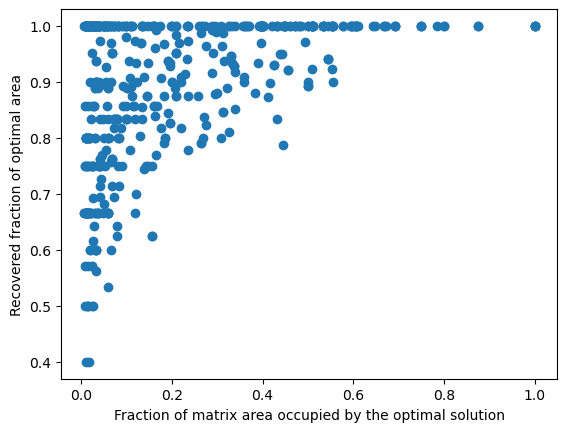

In [144]:
plt.scatter(
    results["optimal_area"] / results["matrix_area"],
    results["areas_ratio"]
)

plt.xlabel("Fraction of matrix area occupied by the optimal solution")
plt.ylabel("Recovered fraction of optimal area")
plt.show()

In [145]:
bins = np.arange(0, 1.1, 0.1)
results["missing_bucket"] = pd.cut(results["missing"], bins=bins, include_lowest = True, right = False)

In [146]:
results_across_missingness = (
    results
    .assign(recovered_90=results["areas_ratio"] >= 0.9)
    .groupby("missing_bucket", observed=True)
    .agg(
        n=("areas_ratio", "size"),
        mean_recovery=("areas_ratio", "mean"),
        median_recovery=("areas_ratio", "median"),
        optimal_rate=("areas_ratio", lambda x: (x == 1).mean()),
        recovery_90_rate=("recovered_90", "mean"),
    )
)
results_across_missingness

,n,mean_recovery,median_recovery,optimal_rate,recovery_90_rate
missing_bucket,,,,,
"[0.0, 0.1)",97,0.978093,1.000000,0.731959,0.938144
"[0.1, 0.2)",67,0.928338,0.951923,0.328358,0.701493
"[0.2, 0.3)",41,0.911196,0.909091,0.268293,0.560976
"[0.3, 0.4)",21,0.853697,0.857143,0.095238,0.333333
"[0.4, 0.5)",49,0.868284,0.857143,0.326531,0.408163
"[0.5, 0.6)",47,0.853755,0.857143,0.319149,0.404255
"[0.6, 0.7)",43,0.860339,0.900000,0.418605,0.534884
"[0.7, 0.8)",42,0.842851,0.894444,0.357143,0.500000
"[0.8, 0.9)",39,0.843956,1.000000,0.512821,0.512821


In [147]:
size_bins = np.arange(0, 900, 10)
size_bins
pd.cut(results["matrix_area"], bins=size_bins, include_lowest = True, right = False)

0      [500, 510)
1      [500, 510)
2      [500, 510)
3      [500, 510)
4      [500, 510)
          ...    
500    [500, 510)
501    [500, 510)
502      [50, 60)
503    [500, 510)
504      [50, 60)
Name: matrix_area, Length: 505, dtype: category
Categories (89, interval[int64, left]): [[0, 10) < [10, 20) < [20, 30) < [30, 40) ... [850, 860) < [860, 870) < [870, 880) < [880, 890)]

In [148]:
size_bins = np.arange(0, 900, 10)
results["size_bucket"] = pd.cut(results["matrix_area"], bins=size_bins, include_lowest = True, right = False)

In [149]:
results_across_size = (
    results
    .assign(recovered_90=results["areas_ratio"] >= 0.9)
    .groupby("size_bucket", observed=True)
    .agg(
        n=("areas_ratio", "size"),
        mean_recovery=("areas_ratio", "mean"),
        median_recovery=("areas_ratio", "median"),
        optimal_rate=("areas_ratio", lambda x: (x == 1).mean()),
        recovery_90_rate=("recovered_90", "mean"),
    )
)
results_across_size

,n,mean_recovery,median_recovery,optimal_rate,recovery_90_rate
size_bucket,,,,,
"[10, 20)",26,1.000000,1.000000,1.000000,1.000000
"[50, 60)",29,0.973262,1.000000,0.827586,0.827586
"[80, 90)",29,0.960345,1.000000,0.793103,0.827586
"[180, 190)",46,0.936875,1.000000,0.630435,0.739130
"[300, 310)",170,0.881404,0.923077,0.394118,0.564706
"[500, 510)",170,0.860557,0.896429,0.264706,0.500000
"[860, 870)",35,0.829290,0.837607,0.171429,0.342857


In [150]:
#TODO results for optimal_area/matrix_size

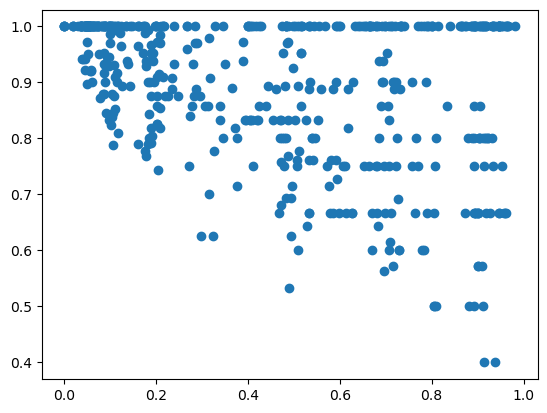

In [151]:
import matplotlib.pyplot as plt

plt.scatter(results["missing"], results["areas_ratio"])
plt.show()

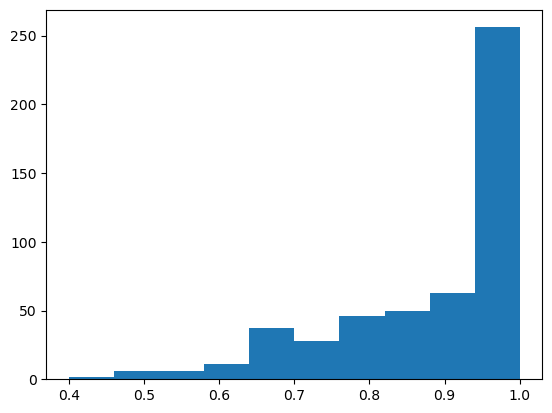

In [152]:
plt.hist(results["areas_ratio"])
plt.show()

In [153]:
missing_mask = ((results["missing"] >= 0) & (results["missing"] <= 0.5))
results_100_ratio_mask = results["areas_ratio"] == 1
results_90_ratio_mask = results["areas_ratio"] >= 0.9
print((missing_mask & results_100_ratio_mask).sum() / len(results[missing_mask]))
print((missing_mask & results_90_ratio_mask).sum() / len(results[missing_mask]))

0.44363636363636366
0.6836363636363636
